# xG: location only versus goalkeeper and defender context

Fit two **nested logistic models** on the same real StatsBomb non-penalty shots:

1. **Location only:** distance to goal and goal-opening angle.
2. **Location + GK/defenders:** the same two inputs, plus goalkeeper positioning and visible defender geometry.

Follow the calculation from data audit through feature geometry, training, held-out predictions, ROC construction and the final AUC comparison. All helpers are inline. No local Python module or prior notebook session is required.

This notebook intentionally uses **StatsBomb shot freeze frames**, as requested, while the rest of the tracking workshop uses SkillCorner. Freeze frames describe visible players at a shot, not full continuous tracking. Data: **StatsBomb Open Data**, men's World Cups 2018 and 2022. [Repository and usage terms](https://github.com/hudl/open-data), [contextual xG discussion](https://statsbomb.com/articles/soccer/upgrading-expected-goals/).

**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports, pinned source and local cache
Raw files are cached under ignored `data/`. First execution downloads shot-event data from 128 matches; later executions reuse the cache. Both datasets and the attribution logo use an immutable source revision. No `statsbomb_xg`, shot endpoint, save outcome or other post-shot field is used as a predictor.

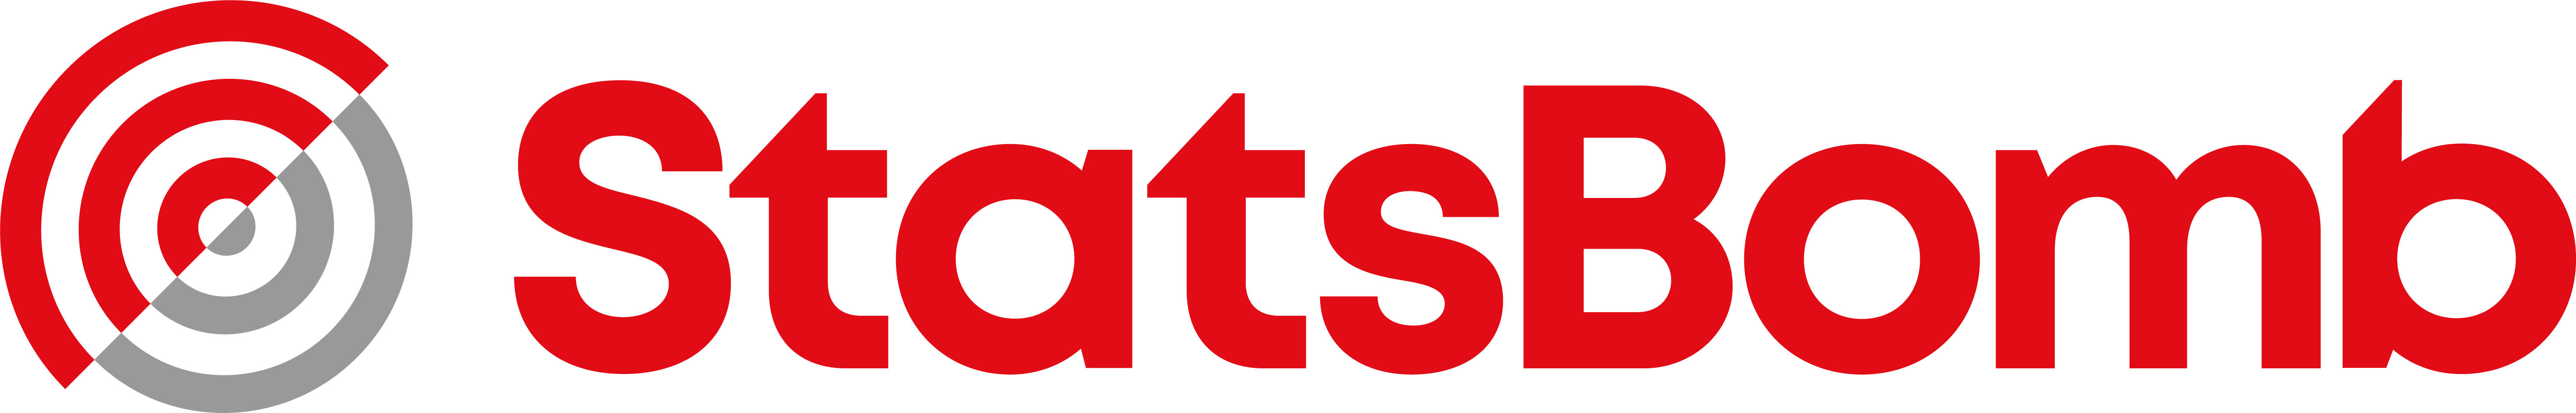

Data source: StatsBomb Open Data. Revision: 4b73468fc5b0f1950f9f66fada70ad3a4f9327cb


In [1]:
from pathlib import Path
import json,urllib.request,time
from concurrent.futures import ThreadPoolExecutor,as_completed
import numpy as np
import pandas as pd

SB_REVISION='4b73468fc5b0f1950f9f66fada70ad3a4f9327cb'
SB_BASE=f'https://raw.githubusercontent.com/hudl/open-data/{SB_REVISION}/'
SEASONS=[(43,3,'2018'),(43,106,'2022')]


import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle,Circle,Polygon
from IPython.display import display,Image
from scipy.optimize import minimize
roots=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in roots if (p/'notebooks/methods').exists()),Path.cwd())
CACHE=ROOT/'data/xg_statsbomb'/SB_REVISION
CACHE.mkdir(parents=True,exist_ok=True)
logo_path=CACHE/'statsbomb_logo.png'
if not logo_path.exists():
    with urllib.request.urlopen(SB_BASE+'img/SB%20-%20Icon%20Lockup%20-%20Colour%20positive.png',timeout=90) as response:logo_path.write_bytes(response.read())
display(Image(filename=str(logo_path),width=200))
print('Data source: StatsBomb Open Data. Revision:',SB_REVISION)

## Choose a shot

After the first complete run, change `SHOT_INDEX`, run its selection cell and rerun the final exploration cell. The existing held-out scores are reused without refitting. This source provides StatsBomb shot freeze frames, not continuous tracking. The explorer therefore compares real shot snapshots and held-out model estimates; it does not invent movement or download a movie.

In [2]:
# Example selection: change the row number, then rerun the analysis below.
SHOT_INDEX = 0  # row number in data; inspect shot_catalog near the end


## 2. Load shots and audit availability
Retain non-penalty shots from periods 1–4, with a visible opposing goalkeeper and at least one visible defender. The goal label is the shot outcome `Goal`; shootouts are excluded. Both models use the **same complete-context cohort**, so a change in AUC reflects a change in features rather than a different set of shots. Counts of exclusions remain visible.

StatsBomb uses a normalized **120 × 80 coordinate grid**, not measured metres. We recenter it to x ∈ [−60,60], y ∈ [−40,40], attacking right. Goalposts become (60, ±4). Every distance below is in **StatsBomb coordinate units**. Do not interpret a three-unit radius as exactly three metres.

In [3]:
def cached_json(relative,path):
    if not path.exists():
        error=None
        for attempt in range(3):
            try:
                with urllib.request.urlopen(SB_BASE+relative,timeout=120) as response:payload=response.read()
                parsed=json.loads(payload);temporary=path.with_suffix('.partial');temporary.write_bytes(payload);temporary.replace(path);return parsed
            except Exception as e:error=e;time.sleep(attempt+1)
        raise error
    return json.loads(path.read_text(encoding='utf-8'))

In [4]:
def event_to_shot(event,match_id,season):
    shot=event.get('shot',{})
    if event.get('type',{}).get('name')!='Shot':return None,'not_shot'
    if int(event.get('period',0))>4:return None,'shootout'
    if shot.get('type',{}).get('name')=='Penalty':return None,'penalty'
    freeze=shot.get('freeze_frame',[])
    if not freeze:return None,'missing_freeze_frame'
    opponents=[p for p in freeze if p.get('teammate') is False and len(p.get('location',[]))>=2]
    keepers=[p for p in opponents if p.get('position',{}).get('name')=='Goalkeeper']
    if len(keepers)!=1:return None,'missing_or_ambiguous_keeper'
    defenders=[p for p in opponents if p.get('position',{}).get('name')!='Goalkeeper']
    if not defenders:return None,'missing_defenders'
    if len(event.get('location',[]))<2:return None,'missing_shot_location'
    def centered(location):return [float(location[0])-60,40-float(location[1])]
    x,y=centered(event['location']);gkx,gky=centered(keepers[0]['location'])
    if x>=59.8:return None,'at_or_beyond_goal_line'
    return dict(match_id=int(match_id),season=season,event_id=event['id'],period=int(event['period']),goal=int(shot['outcome']['name']=='Goal'),x=x,y=y,goal_x=60.,gk_x=gkx,gk_y=gky,defender_positions=[centered(p['location']) for p in defenders],defenders_visible=len(defenders)),None

In [5]:
def load_statsbomb_shots(cache,workers=6):
    cache.mkdir(parents=True,exist_ok=True);jobs=[]
    for competition,season,label in SEASONS:
        matches=cached_json(f'data/matches/{competition}/{season}.json',cache/f'matches_{competition}_{season}.json')
        jobs.extend((m['match_id'],label) for m in matches)
    def one(job):
        match_id,season=job;path=cache/f'shots_{match_id}.json'
        if path.exists():events=json.loads(path.read_text(encoding='utf-8'))
        else:
            # Store only original shot-event objects locally; never publish these raw files.
            with urllib.request.urlopen(SB_BASE+f'data/events/{match_id}.json',timeout=120) as response:all_events=json.load(response)
            events=[e for e in all_events if e.get('type',{}).get('name')=='Shot']
            temporary=path.with_suffix('.partial');temporary.write_text(json.dumps(events),encoding='utf-8');temporary.replace(path)
        rows=[];exclusions={}
        for event in events:
            row,reason=event_to_shot(event,match_id,season)
            if row is not None:rows.append(row)
            else:exclusions[reason]=exclusions.get(reason,0)+1
        return rows,dict(match_id=match_id,season=season,raw_shots=len(events),eligible_shots=len(rows),goals=sum(r['goal'] for r in rows),exclusions=exclusions)
    rows=[];audits=[]
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for i,future in enumerate(as_completed([pool.submit(one,j) for j in jobs]),1):
            r,a=future.result();rows.extend(r);audits.append(a)
            if i%16==0:print('Loaded',i,'/',len(jobs),'matches',flush=True)
    return pd.DataFrame(rows).sort_values(['match_id','event_id']).reset_index(drop=True),pd.DataFrame(audits).sort_values('match_id')

In [6]:
shots,audit=load_statsbomb_shots(CACHE)
assert not shots.duplicated(['match_id','event_id']).any()
display(audit.groupby('season')[['raw_shots','eligible_shots','goals']].sum())
excluded={}
for reasons in audit.exclusions:
    for reason,count in reasons.items():excluded[reason]=excluded.get(reason,0)+count
display(pd.Series(excluded,name='Excluded shots').sort_values(ascending=False))
print('Eligible shots:',len(shots),'| goals:',int(shots.goal.sum()),'| matches:',shots.match_id.nunique())

Loaded 16 / 128 matches


Loaded 32 / 128 matches


Loaded 48 / 128 matches


Loaded 64 / 128 matches


Loaded 80 / 128 matches


...

Loaded 112 / 128 matches


Loaded 128 / 128 matches


,raw_shots,eligible_shots,goals
season,,,
2018,1706,1637,135
2022,1494,1429,152


shootout                       80
penalty                        52
missing_or_ambiguous_keeper     1
at_or_beyond_goal_line          1
Name: Excluded shots, dtype: int64

Eligible shots: 3066 | goals: 287 | matches: 128


## 3. Inspect location features before fitting the baseline
Compute vectors from the shooter to both posts. Their opening angle and distance to the center of goal are the baseline's only predictors. Then inspect a real freeze frame's shot location without adding context yet.

,distance_units,opening_angle_rad
0,10.198039,0.737815
1,16.643317,0.405354
2,10.198039,0.737815
3,20.000000,0.244979
4,28.017851,0.283445
5,15.000000,0.331765
6,22.627417,0.252554
7,13.038405,0.593973


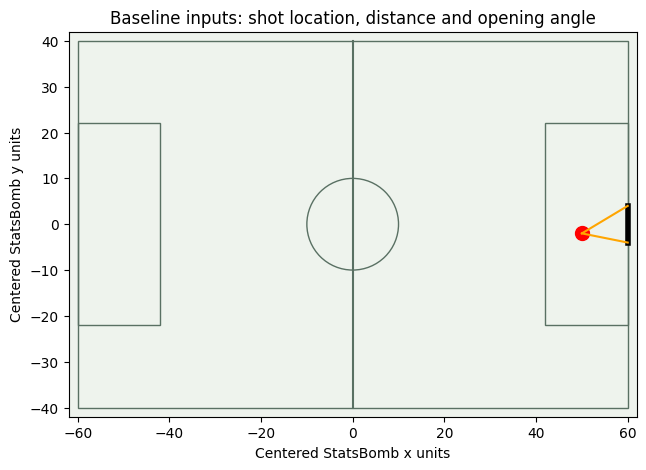

In [7]:
def location_features(shots):
    rows=[]
    for s in shots.itertuples():
        shooter=np.array([s.x,s.y]);goal=np.array([s.goal_x,0.]);a=np.array([s.goal_x,-4.])-shooter;b=np.array([s.goal_x,4.])-shooter
        angle=np.arccos(np.clip(a@b/(np.linalg.norm(a)*np.linalg.norm(b)),-1,1))
        rows.append({'distance_units':np.linalg.norm(goal-shooter),'opening_angle_rad':angle})
    return pd.DataFrame(rows)
def draw_pitch(ax):
    ax.set_facecolor('#eef3ed');ax.add_patch(Rectangle((-60,-40),120,80,fill=False,color='#597063'));ax.plot([0,0],[-40,40],c='#597063');ax.add_patch(Circle((0,0),10,fill=False,color='#597063'))
    for x in [-60,42]:ax.add_patch(Rectangle((x,-22),18,44,fill=False,color='#597063'))
    ax.plot([60,60],[-4,4],lw=4,c='black');ax.set(xlim=(-62,62),ylim=(-42,42),aspect='equal',xlabel='Centered StatsBomb x units',ylabel='Centered StatsBomb y units')
location=location_features(shots);display(location.head(8))
example=shots.iloc[0];fig,ax=plt.subplots(figsize=(10,5));draw_pitch(ax);ax.scatter(example.x,example.y,c='red',s=100)
for y in [-4,4]:ax.plot([example.x,60],[example.y,y],c='orange')
ax.set_title('Baseline inputs: shot location, distance and opening angle');plt.show()

## 4. Add goalkeeper and defender context
For the contextual model, calculate goalkeeper distance to shooter, goalkeeper distance to goal, perpendicular offset from the shooter–goal-center line, visible defenders in the shot triangle, nearest visible defender distance, and visible defenders within three coordinate units. Keep these definitions explicit: they are simple engineered features, not StatsBomb's production model.

,goal,distance_units,opening_angle_rad,gk_shooter_distance_units,gk_goal_distance_units,gk_off_shot_line_units,defenders_in_triangle,nearest_defender_units,defenders_within_3_units
0,0,10.198039,0.737815,7.280110,3.000000,0.588348,1,3.162278,0
1,0,16.643317,0.405354,13.416408,3.605551,1.442020,0,1.000000,2
2,0,10.198039,0.737815,9.219544,1.000000,0.196116,1,2.000000,1
3,0,20.000000,0.244979,18.027756,2.236068,1.000000,1,1.414214,1
4,0,28.017851,0.283445,25.079872,3.162278,1.106437,0,4.000000,0
5,0,15.000000,0.331765,12.041595,4.000000,2.400000,1,1.414214,1
6,0,22.627417,0.252554,20.518285,2.236068,0.707107,1,1.000000,1
7,0,13.038405,0.593973,10.049876,3.000000,0.230089,0,1.414214,1


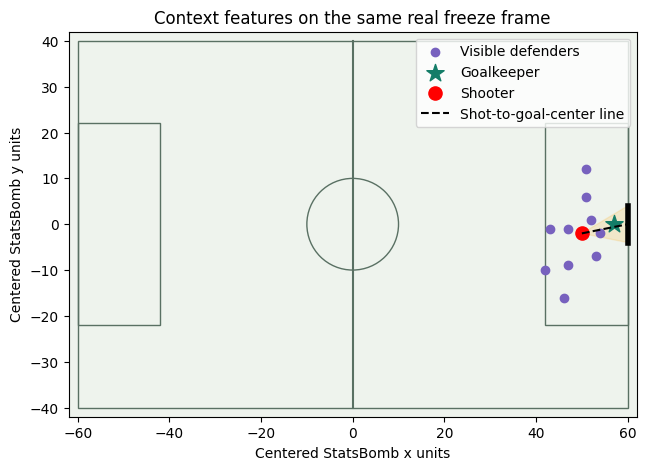

In [8]:
def contextual_features(shots):
    rows=[]
    for s in shots.itertuples():
        shooter=np.array([s.x,s.y]);goal=np.array([s.goal_x,0.]);keeper=np.array([s.gk_x,s.gk_y]);defenders=np.asarray(s.defender_positions,float)
        to_goal=goal-shooter;distance=np.linalg.norm(to_goal)
        fraction=(defenders[:,0]-s.x)/(s.goal_x-s.x)
        lower=s.y+fraction*(-4-s.y);upper=s.y+fraction*(4-s.y)
        in_triangle=(fraction>0)&(fraction<1)&(defenders[:,1]>=lower)&(defenders[:,1]<=upper)
        defender_distance=np.linalg.norm(defenders-shooter,axis=1)
        off_line=abs(to_goal[0]*(keeper[1]-s.y)-to_goal[1]*(keeper[0]-s.x))/distance
        rows.append({'gk_shooter_distance_units':np.linalg.norm(keeper-shooter),'gk_goal_distance_units':np.linalg.norm(keeper-goal),'gk_off_shot_line_units':off_line,'defenders_in_triangle':int(in_triangle.sum()),'nearest_defender_units':defender_distance.min(),'defenders_within_3_units':int((defender_distance<=3).sum())})
    return pd.DataFrame(rows)
context=contextual_features(shots)
data=pd.concat([shots.reset_index(drop=True),location,context],axis=1)
LOCATION_FEATURES=list(location.columns)
CONTEXT_FEATURES=LOCATION_FEATURES+list(context.columns)
assert np.isfinite(data[CONTEXT_FEATURES].to_numpy()).all()
display(data[['goal']+CONTEXT_FEATURES].head(8))
fig,ax=plt.subplots(figsize=(10,5));draw_pitch(ax)
d=np.asarray(example.defender_positions);ax.add_patch(Polygon([[example.x,example.y],[60,-4],[60,4]],alpha=.15,color='orange'))
ax.scatter(d[:,0],d[:,1],c='#7761be',label='Visible defenders');ax.scatter(example.gk_x,example.gk_y,c='#147d68',marker='*',s=170,label='Goalkeeper');ax.scatter(example.x,example.y,c='red',s=90,label='Shooter')
ax.plot([example.x,60],[example.y,0],ls='--',c='black',label='Shot-to-goal-center line');ax.legend();ax.set_title('Context features on the same real freeze frame');plt.show()

## 5. Inspect the logistic objective and gradient
Both models use the same logistic learner and a fixed L2 penalty (0.01), applied only to non-intercept weights. Inspect and finite-difference-check its gradient before fitting. Scaling and centering in the actual models are learned **only on each training fold**. No class weighting or outcome resampling changes the goal prevalence.

In [9]:
def sigmoid(score):return 1/(1+np.exp(-np.clip(score,-40,40)))

def logistic_loss_gradient(weights,design,y,l2):
    score=design@weights;probability=sigmoid(score)
    penalty=weights.copy();penalty[0]=0
    loss=np.mean(np.logaddexp(0,score)-y*score)+l2/2*(penalty@penalty)
    gradient=design.T@(probability-y)/len(y)+l2*penalty
    return loss,gradient

In [10]:
design=np.array([[1.,-.5,.2],[1.,.5,-.2],[1.,1.,.1]])
y_check=np.array([0.,1.,0.]);w_check=np.array([.1,-.2,.3]);loss,gradient=logistic_loss_gradient(w_check,design,y_check,.01)
epsilon=1e-5;plus=w_check.copy();minus=w_check.copy();plus[1]+=epsilon;minus[1]-=epsilon
numeric=(logistic_loss_gradient(plus,design,y_check,.01)[0]-logistic_loss_gradient(minus,design,y_check,.01)[0])/(2*epsilon)
assert np.isclose(gradient[1],numeric,rtol=1e-5,atol=1e-7)
display(pd.DataFrame({'weight':w_check,'gradient':gradient,'one_step_update':w_check-.1*gradient}))

,weight,gradient,one_step_update
0,0.1,0.177383,0.082262
1,-0.2,-0.021103,-0.197890
2,0.3,0.091059,0.290894


In [11]:
def fit_logistic(X,y,l2=.01):
    X=np.asarray(X,float);y=np.asarray(y,float)
    if len(np.unique(y))<2:raise ValueError('Training fold needs both classes')
    mean=X.mean(axis=0);scale=X.std(axis=0);scale[scale<1e-8]=1
    design=np.c_[np.ones(len(X)),(X-mean)/scale]
    start=np.zeros(design.shape[1]);start[0]=np.log(y.mean()/(1-y.mean()))
    result=minimize(logistic_loss_gradient,start,args=(design,y,l2),method='L-BFGS-B',jac=True,options={'maxiter':1000,'ftol':1e-12,'gtol':1e-8})
    if not result.success:raise RuntimeError(result.message)
    return dict(weights=result.x,mean=mean,scale=scale,iterations=result.nit,loss=result.fun)

def predict_logistic(model,X):
    X=np.asarray(X,float);design=np.c_[np.ones(len(X)),(X-model['mean'])/model['scale']]
    return sigmoid(design@model['weights'])

## 6. Hold out whole matches in identical folds
Create five deterministic match-level folds. Every shot receives a prediction from a model trained without **any shots from that match**. Both models share those folds and the same eligible rows. These are pooled out-of-fold estimates, not training-set ROC curves or a prospective external tournament test.

In [12]:
def assign_match_folds(data,n_folds=5,seed=27):
    matches=np.sort(data.match_id.unique());rng=np.random.default_rng(seed);rng.shuffle(matches)
    mapping={int(match):i for i,group in enumerate(np.array_split(matches,n_folds)) for match in group}
    return data.match_id.map(mapping).to_numpy()
fold_plan=assign_match_folds(data)
display(data.assign(fold=fold_plan).groupby('fold').agg(matches=('match_id','nunique'),shots=('goal','size'),goals=('goal','sum')))

,matches,shots,goals
fold,,,
0,26,577,65
1,26,663,61
2,26,649,57
3,25,571,51
4,25,606,53


In [13]:
def grouped_oof_predictions(data,feature_sets,n_folds=5,seed=27,l2=.01):
    folds=assign_match_folds(data,n_folds,seed);y=data.goal.to_numpy(int)
    predictions={name:np.full(len(data),np.nan) for name in feature_sets};audit=[]
    for fold in range(n_folds):
        test=folds==fold;train=~test
        assert not set(data.loc[train,'match_id'])&set(data.loc[test,'match_id'])
        for name,features in feature_sets.items():
            model=fit_logistic(data.loc[train,features],y[train],l2=l2)
            predictions[name][test]=predict_logistic(model,data.loc[test,features])
        audit.append(dict(fold=fold,train_matches=data.loc[train,'match_id'].nunique(),test_matches=data.loc[test,'match_id'].nunique(),train_shots=int(train.sum()),test_shots=int(test.sum()),train_goals=int(y[train].sum()),test_goals=int(y[test].sum())))
    assert all(np.isfinite(p).all() for p in predictions.values())
    return predictions,folds,pd.DataFrame(audit)

In [14]:
feature_sets={'Location only':LOCATION_FEATURES,'Location + GK/defenders':CONTEXT_FEATURES}
predictions,folds,fold_audit=grouped_oof_predictions(data,feature_sets)
assert np.array_equal(folds,fold_plan)
display(fold_audit)
display(pd.DataFrame({'goal':data.goal.head(8),**{name:p[:8] for name,p in predictions.items()}}))

,fold,train_matches,test_matches,train_shots,test_shots,train_goals,test_goals
0,0,102,26,2489,577,222,65
1,1,102,26,2403,663,226,61
2,2,102,26,2417,649,230,57
3,3,103,25,2495,571,236,51
4,4,103,25,2460,606,234,53


,goal,Location only,Location + GK/defenders
0,0,0.157983,0.178895
1,0,0.071706,0.061895
2,0,0.157983,0.112736
3,0,0.047199,0.030160
4,0,0.030048,0.035022
5,0,0.071971,0.064801
6,0,0.040469,0.023876
7,0,0.112980,0.111692


## 7. Construct ROC points from held-out scores
A ROC curve sweeps the classification threshold and plots true-positive rate against false-positive rate. **AUC is the area under that ROC curve**, rather than a separate kind of curve. Sort scores, process ties together and count cumulative positives/negatives. Inspect the threshold table before plotting the final comparison.

In [15]:
def roc_curve_auc(y,probability):
    y=np.asarray(y,int);probability=np.asarray(probability,float)
    if len(np.unique(y))<2:raise ValueError('ROC requires positives and negatives')
    order=np.argsort(-probability,kind='mergesort');score=probability[order];labels=y[order]
    ends=np.r_[np.flatnonzero(np.diff(score)),len(score)-1]
    positives=labels.cumsum()[ends];negatives=(ends+1)-positives
    tpr=np.r_[0,positives/labels.sum()];fpr=np.r_[0,negatives/(len(labels)-labels.sum())]
    thresholds=np.r_[np.inf,score[ends]]
    return fpr,tpr,thresholds,float(np.trapezoid(tpr,fpr))

In [16]:
assert np.isclose(roc_curve_auc([0,1],[.5,.5])[-1],.5)
assert np.isclose(roc_curve_auc([0,1],[.1,.9])[-1],1.)
curves={name:roc_curve_auc(data.goal,p) for name,p in predictions.items()}
name='Location only';fpr,tpr,thresholds,auc=curves[name]
display(pd.DataFrame({'threshold':thresholds,'false_positive_rate':fpr,'true_positive_rate':tpr}).iloc[::max(1,len(fpr)//12)])

,threshold,false_positive_rate,true_positive_rate
0,inf,0.000000,0.000000
220,0.201409,0.069449,0.303136
440,0.138910,0.155811,0.459930
660,0.109990,0.236416,0.585366
880,0.088847,0.318100,0.689895
1100,0.075370,0.403023,0.777003
1320,0.063772,0.485786,0.832753
1540,0.054131,0.571429,0.871080
1760,0.047085,0.660309,0.885017
1980,0.040638,0.744153,0.923345


## 8. Quantify uncertainty by resampling matches
Bootstrap whole matches, keeping the two predictions paired on identical resamples. This gives percentile intervals for each pooled AUC and their difference. It captures variation in the evaluated match sample **conditional on the existing out-of-fold predictions**; it does not retrain models in every bootstrap draw and is not a full measure of training or domain-shift uncertainty.

In [17]:
def cluster_bootstrap_auc(data,predictions,repeats=1000,seed=9):
    rng=np.random.default_rng(seed);matches=data.match_id.unique();indices={m:np.flatnonzero(data.match_id.to_numpy()==m) for m in matches};y=data.goal.to_numpy(int);rows=[]
    for _ in range(repeats):
        selected=rng.choice(matches,len(matches),replace=True);idx=np.concatenate([indices[m] for m in selected])
        if len(np.unique(y[idx]))<2:continue
        row={name:roc_curve_auc(y[idx],p[idx])[-1] for name,p in predictions.items()}
        row['context_minus_location']=row['Location + GK/defenders']-row['Location only'];rows.append(row)
    return pd.DataFrame(rows)

In [18]:
bootstrap=cluster_bootstrap_auc(data,predictions,repeats=1000)
intervals=bootstrap.quantile([.025,.975])
display(intervals.T.rename(columns={.025:'95% lower',.975:'95% upper'}))

,95% lower,95% upper
Location only,0.713895,0.774165
Location + GK/defenders,0.749411,0.809066
context_minus_location,0.021778,0.051104


## 9. Final comparison: ROC curves and AUC for both models
Show each ROC separately and overlay them on the same axes. A higher contextual AUC is an observed result of this experiment, not a guaranteed consequence of adding features. A paired AUC-difference interval crossing zero weakens a claim of improvement. Also show log loss and Brier score because AUC measures ranking, not calibrated xG probabilities.

C:\Users\zcoch\AppData\Local\Temp\ipykernel_43080\1695147232.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0,.06,1,.94))


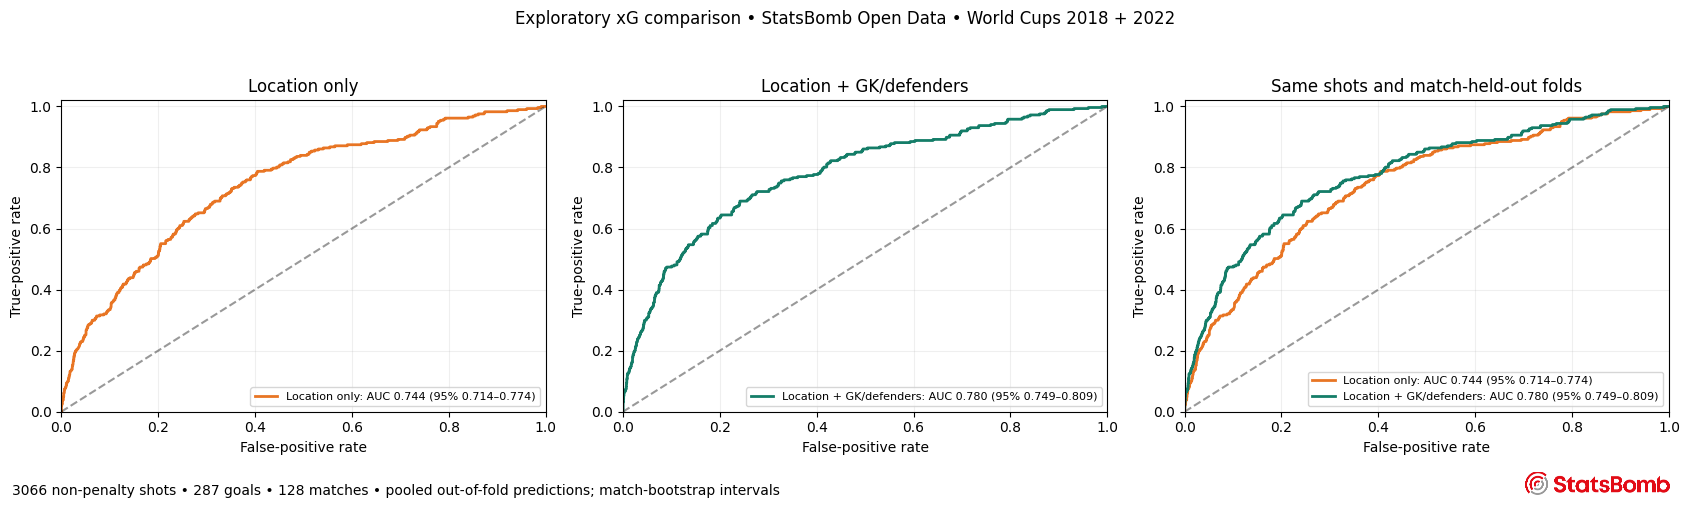

,model,ROC_AUC,AUC_95_lower,AUC_95_upper,log_loss,Brier_score
0,Location only,0.743879,0.713895,0.774165,0.275541,0.077315
1,Location + GK/defenders,0.779870,0.749411,0.809066,0.261103,0.073461


Context − location AUC: +0.036; paired match-bootstrap 95% interval [+0.022, +0.051]


1387

In [19]:
colors={'Location only':'#e87524','Location + GK/defenders':'#147d68'}
fig,axs=plt.subplots(1,3,figsize=(17,5))
rows=[];y=data.goal.to_numpy(int)
for i,(name,p) in enumerate(predictions.items()):
    fpr,tpr,_,auc=curves[name];lo,hi=intervals[name].to_numpy();label=f'{name}: AUC {auc:.3f} (95% {lo:.3f}–{hi:.3f})'
    axs[i].plot(fpr,tpr,c=colors[name],lw=2,label=label);axs[i].set_title(name);axs[i].legend(loc='lower right',fontsize=8)
    axs[2].plot(fpr,tpr,c=colors[name],lw=2,label=label)
    clipped=np.clip(p,1e-8,1-1e-8)
    rows.append({'model':name,'ROC_AUC':auc,'AUC_95_lower':lo,'AUC_95_upper':hi,'log_loss':float(-(y*np.log(clipped)+(1-y)*np.log(1-clipped)).mean()),'Brier_score':float(np.mean((p-y)**2))})
for ax in axs:ax.plot([0,1],[0,1],'k--',alpha=.4);ax.set(xlim=(0,1),ylim=(0,1.02),xlabel='False-positive rate',ylabel='True-positive rate');ax.grid(alpha=.2)
axs[2].set_title('Same shots and match-held-out folds');axs[2].legend(loc='lower right',fontsize=8)
fig.suptitle('Exploratory xG comparison • StatsBomb Open Data • World Cups 2018 + 2022')
fig.text(.01,.01,f'{len(data)} non-penalty shots • {int(y.sum())} goals • {data.match_id.nunique()} matches • pooled out-of-fold predictions; match-bootstrap intervals',fontsize=10)
logo_ax=fig.add_axes([.90,.008,.085,.05]);logo_ax.imshow(plt.imread(logo_path));logo_ax.axis('off')
fig.tight_layout(rect=(0,.06,1,.94))
output=ROOT/'outputs/methods';output.mkdir(parents=True,exist_ok=True)
figure_dir=ROOT/'assets/methods';figure_dir.mkdir(parents=True,exist_ok=True)
fig.savefig(figure_dir/'xg_roc_comparison.png',dpi=170,bbox_inches='tight');plt.show()
results=pd.DataFrame(rows);display(results)
delta=curves['Location + GK/defenders'][-1]-curves['Location only'][-1]
delta_low,delta_high=intervals['context_minus_location'].to_numpy()
print(f'Context − location AUC: {delta:+.3f}; paired match-bootstrap 95% interval [{delta_low:+.3f}, {delta_high:+.3f}]')
report={'data_source':'StatsBomb Open Data','revision':SB_REVISION,'seasons':['World Cup 2018','World Cup 2022'],'shots':len(data),'goals':int(y.sum()),'matches':int(data.match_id.nunique()),'location_features':LOCATION_FEATURES,'context_features':CONTEXT_FEATURES,'l2':.01,'folds':5,'fold_seed':27,'evaluation':'pooled match-grouped out-of-fold predictions','bootstrap':'1000 paired match resamples of existing predictions; no retraining','results':rows,'auc_difference':delta,'auc_difference_95':[delta_low,delta_high]}
(output/'xg_model_comparison.json').write_text(json.dumps(report,indent=2)+'\n',encoding='utf-8')

## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,shot_index,match_id,event_id,goal,x,y
0,0,7525,01a65652-f30d-4eec-a312-35bb2f276ec8,0,50.0,-2.0
1,1,7525,10a1cd4a-ce60-4ab3-b091-82777ec8a2bb,0,46.0,-9.0
2,2,7525,1ac0f8cc-2fb7-4075-ab6b-ea88e10ec5ff,0,50.0,-2.0
3,3,7525,2309342e-7c8b-4fb6-9705-bbe743232dea,0,48.0,16.0
4,4,7525,2c1f0620-adf2-4c5d-9392-eba1aeea1036,0,32.0,1.0
5,5,7525,2ca29ab6-97c7-482e-bba9-1b2b956f7bda,0,51.0,-12.0
6,6,7525,5cfdb2d1-7aca-4b3b-8a0c-61d6cce1788c,0,44.0,-16.0
7,7,7525,5f4bebcc-4098-4d9a-9d9d-723eac8dcf3e,0,47.0,1.0
8,8,7525,6bb8de4d-ece7-4f7c-8ab3-797b9304d5f5,0,44.0,-17.0
9,9,7525,780993c0-98d3-4656-acde-8424eaad980c,1,44.0,17.0


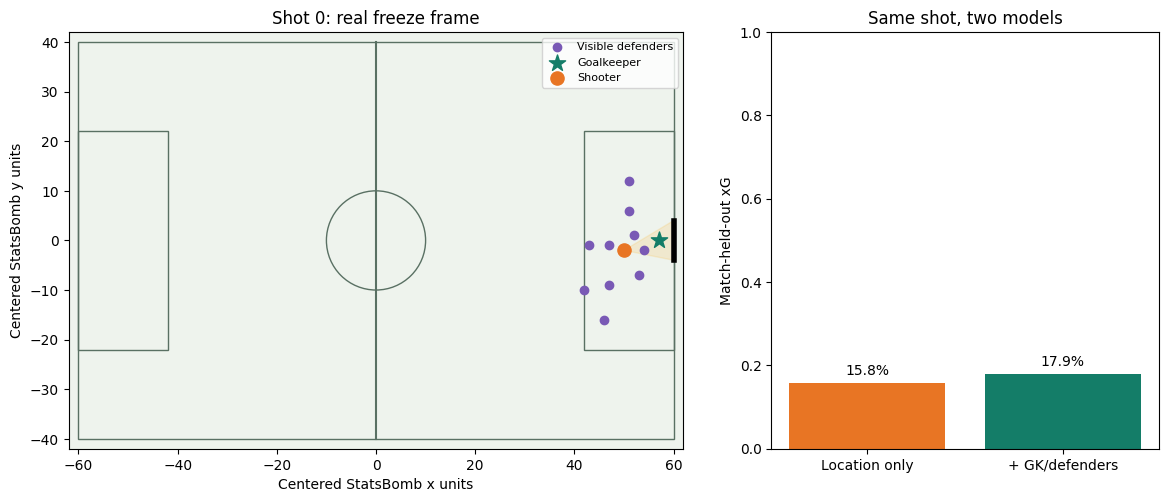

,event_id,goal,distance_units,opening_angle_rad,gk_shooter_distance_units,gk_goal_distance_units,gk_off_shot_line_units,defenders_in_triangle,nearest_defender_units,defenders_within_3_units
0,01a65652-f30d-4eec-a312-35bb2f276ec8,0,10.198039,0.737815,7.28011,3.0,0.588348,1,3.162278,0


In [20]:
shot_catalog=data[['match_id','event_id','goal','x','y']].reset_index(names='shot_index')
display(shot_catalog.head(20))
assert 0<=SHOT_INDEX<len(data),'Choose SHOT_INDEX from shot_catalog.shot_index.'
selected_shot=data.iloc[SHOT_INDEX]
fig,(ax,bx)=plt.subplots(1,2,figsize=(12,5),gridspec_kw={'width_ratios':[1.7,1]})
draw_pitch(ax);defender_xy=np.asarray(selected_shot.defender_positions)
ax.add_patch(Polygon([[selected_shot.x,selected_shot.y],[60,-4],[60,4]],alpha=.13,color='orange'))
ax.scatter(*defender_xy.T,c='#7959b5',label='Visible defenders');ax.scatter(selected_shot.gk_x,selected_shot.gk_y,c='#147d68',marker='*',s=150,label='Goalkeeper');ax.scatter(selected_shot.x,selected_shot.y,c='#e87524',s=90,label='Shooter');ax.legend(fontsize=8);ax.set_title(f'Shot {SHOT_INDEX}: real freeze frame')
model_names=list(predictions);values=[predictions[name][SHOT_INDEX] for name in model_names]
bx.bar(['Location only','+ GK/defenders'],values,color=['#e87524','#147d68']);bx.set(ylabel='Match-held-out xG',ylim=(0,1),title='Same shot, two models')
for i,value in enumerate(values):bx.text(i,value+.02,f'{value:.1%}',ha='center')
plt.tight_layout();plt.show();display(data.loc[[SHOT_INDEX],['event_id','goal']+CONTEXT_FEATURES])
# Verify a second real shot can be analyzed without refitting or changing folds.
assert len(data)>1 and all(np.isfinite(predictions[name][(SHOT_INDEX+1)%len(data)]) for name in model_names)


## Interpretation and limitations
- The location-only model keeps the original distance-and-angle idea; the second adds only pre-shot goalkeeper/defender geometry. Learner, regularization, shots and folds are identical.
- These are transparent workshop models, **not StatsBomb's production xG model**. Headers, body part, shot technique, game state and other potential predictors are intentionally omitted from both.
- Freeze frames contain visible players, so a missing defender is not evidence of an open lane. Requiring keeper/defender context also changes which shots are represented; both models deliberately use that same restricted cohort.
- Distance features use StatsBomb coordinate units, not physical metres. Instantaneous freeze frames do not provide the full movement history available in tracking data.
- Match-held-out cross-validation reduces adjacent-event leakage but can share teams and players across folds. The two tournaments do not establish transfer to club football or a future competition. The bootstrap intervals omit refitting uncertainty.
- ROC/AUC measures discrimination. Log loss and Brier score add probability-quality checks, but calibration and external validation are still needed before using these probabilities operationally.

**Data attribution:** StatsBomb Open Data, [official repository and terms](https://github.com/hudl/open-data). Raw data are cached locally and excluded from publication. The logo is shown above and on the exported ROC figure.